[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WesleyInfoBr2/cienciadedados/blob/main/capitulos/cap07_inferencia/exemplo_distribuicoes_amostrais_tlc.ipynb)

# Distribuições amostrais e o Teorema do Limite Central

Neste exemplo, será simulada uma população assimétrica e serão geradas repetidamente amostras de diferentes tamanhos. A análise compara a distribuição dos valores individuais com as distribuições das médias amostrais e examina como o erro padrão varia com o tamanho da amostra.

## 1. Contexto e perguntas

O Teorema do Limite Central descreve o comportamento da distribuição das médias amostrais quando se repetem amostragens de uma população. Nesta prática, a população simulada tem distribuição assimétrica à direita. A partir dela, serão extraídas amostras de tamanhos distintos, sempre com reposição.

As análises buscam responder:

1. Como é a distribuição dos valores individuais da população simulada?
2. Como se comportam as distribuições das médias amostrais para diferentes tamanhos de amostra?
3. As médias amostrais se concentram em torno da média populacional?
4. Como o erro padrão observado se compara ao erro padrão teórico?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMENTE = 2026
TAMANHO_POPULACAO = 200_000
NUMERO_REPETICOES = 5_000
TAMANHOS_AMOSTRA = [2, 5, 10, 30, 100]

rng = np.random.default_rng(SEMENTE)

# População simulada com distribuição exponencial.
# Para essa distribuição, a média teórica e o desvio-padrão teórico
# são iguais ao parâmetro scale, definido aqui como 10.
PARAMETRO_ESCALA = 10

populacao = rng.exponential(
    scale=PARAMETRO_ESCALA,
    size=TAMANHO_POPULACAO
)

media_populacional = populacao.mean()
desvio_padrao_populacional = populacao.std(ddof=0)

print(f"Semente aleatória: {SEMENTE}")
print(f"Tamanho da população simulada: {TAMANHO_POPULACAO:,}".replace(",", "."))
print(f"Média observada na população: {media_populacional:.3f}")
print(f"Desvio-padrão observado na população: {desvio_padrao_populacional:.3f}")

Semente aleatória: 2026
Tamanho da população simulada: 200.000
Média observada na população: 9.949
Desvio-padrão observado na população: 9.990


## 2. Pergunta: como se distribuem os valores individuais?

O histograma permite observar a forma da distribuição dos valores da população simulada. Como a população foi gerada por uma distribuição exponencial, espera-se uma concentração de valores menores e uma cauda à direita. A curva não deve ser interpretada como uma distribuição normal.

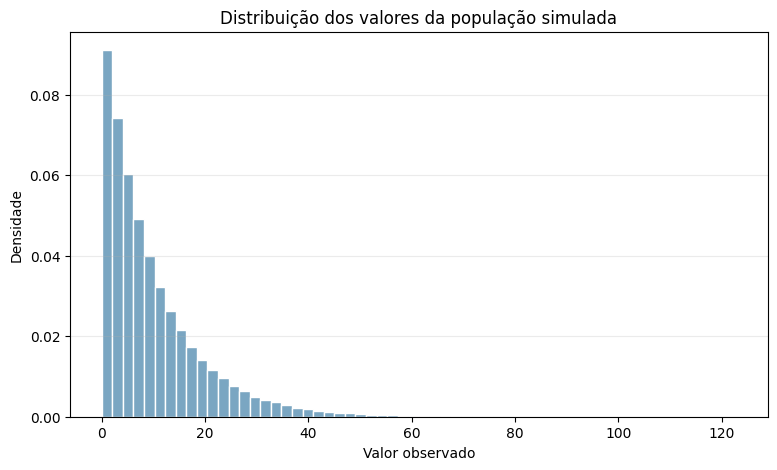

In [2]:
plt.figure(figsize=(9, 5))
plt.hist(
    populacao,
    bins=60,
    density=True,
    color="#7aa6c2",
    edgecolor="white"
)
plt.title("Distribuição dos valores da população simulada")
plt.xlabel("Valor observado")
plt.ylabel("Densidade")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 3. Geração das distribuições de médias amostrais

Para cada tamanho de amostra, são geradas 5.000 amostras independentes, com reposição. Cada observação registrada nesta etapa é a média de uma amostra, e não um valor individual da população.

Como a amostragem é feita com reposição a partir da população simulada, o erro padrão teórico da média amostral é calculado por:

$$
EP(\bar{X}) = \frac{\sigma}{\sqrt{n}}
$$

em que $\sigma$ é o desvio-padrão da população simulada e $n$ é o tamanho da amostra.

In [3]:
medias_amostrais = {}

for tamanho in TAMANHOS_AMOSTRA:
    amostras = rng.choice(
        populacao,
        size=(NUMERO_REPETICOES, tamanho),
        replace=True
    )
    medias_amostrais[tamanho] = amostras.mean(axis=1)

print("Número de médias amostrais geradas por tamanho:", NUMERO_REPETICOES)

Número de médias amostrais geradas por tamanho: 5000


## 4. Pergunta: as distribuições das médias se aproximam de uma distribuição normal?

Os histogramas seguintes mostram a distribuição das médias amostrais para cada tamanho de amostra. A curva normal sobreposta usa a média populacional e o erro padrão teórico correspondente a cada tamanho.

A comparação permite observar o efeito do tamanho amostral. O Teorema do Limite Central não afirma que os dados individuais se tornam normais. Ele descreve a distribuição das médias amostrais, sob condições apropriadas, à medida que o tamanho da amostra aumenta.

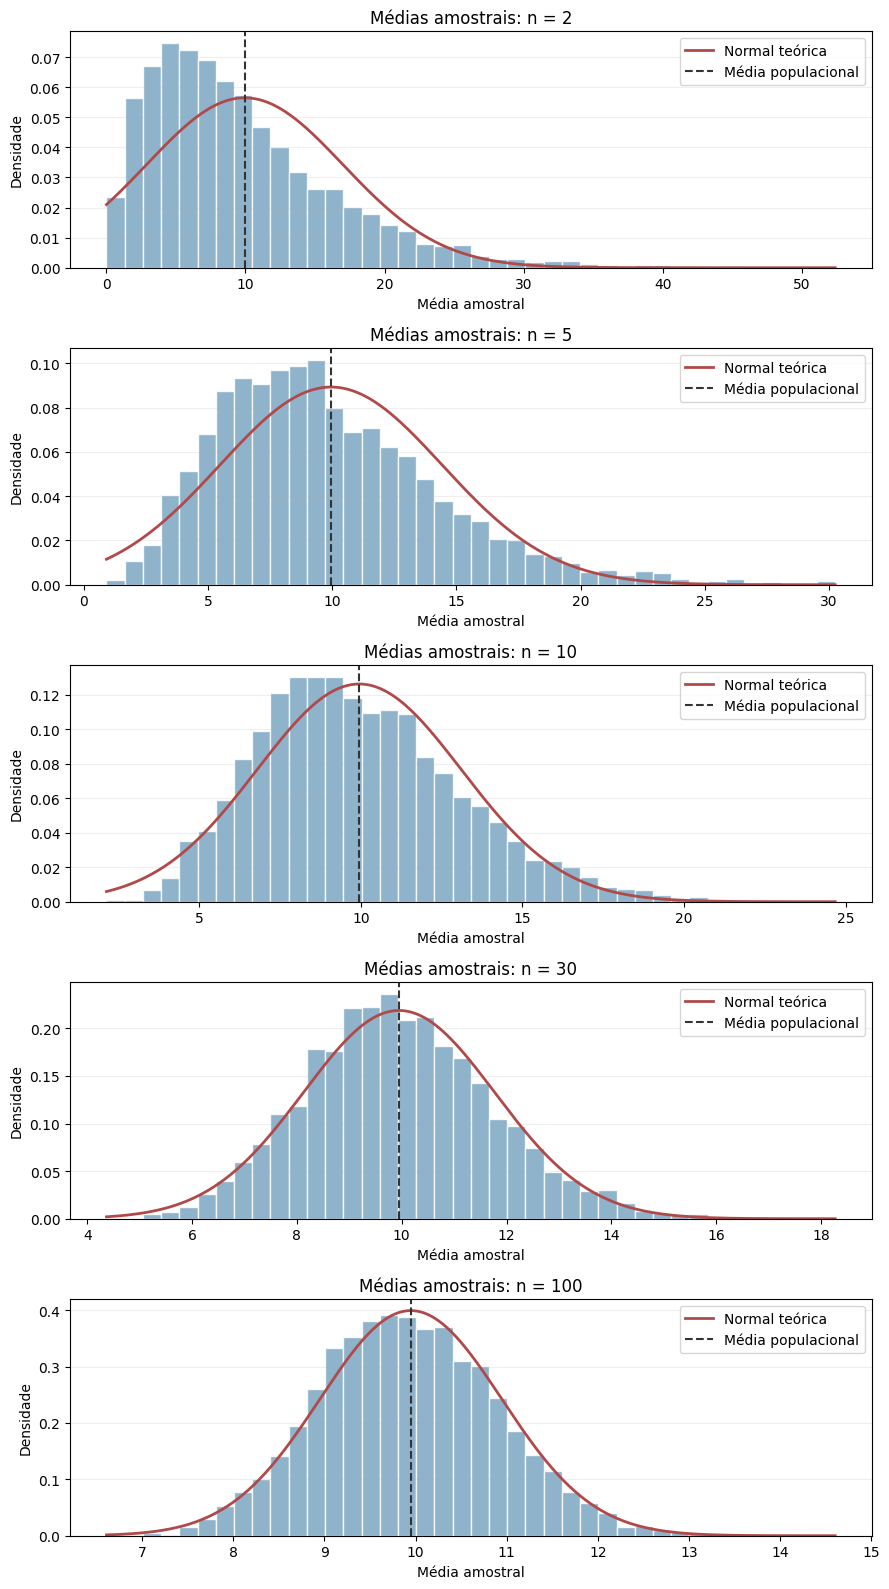

In [4]:
numero_graficos = len(TAMANHOS_AMOSTRA)
fig, eixos = plt.subplots(
    numero_graficos,
    1,
    figsize=(9, 3.2 * numero_graficos)
)

for eixo, tamanho in zip(eixos, TAMANHOS_AMOSTRA):
    medias = medias_amostrais[tamanho]
    erro_padrao_teorico = desvio_padrao_populacional / np.sqrt(tamanho)

    eixo.hist(
        medias,
        bins=40,
        density=True,
        color="#7aa6c2",
        edgecolor="white",
        alpha=0.85
    )

    valores_x = np.linspace(medias.min(), medias.max(), 400)
    densidade_normal = (
        1 / (erro_padrao_teorico * np.sqrt(2 * np.pi))
        * np.exp(
            -0.5
            * ((valores_x - media_populacional) / erro_padrao_teorico) ** 2
        )
    )

    eixo.plot(
        valores_x,
        densidade_normal,
        color="#b04a4a",
        linewidth=2,
        label="Normal teórica"
    )

    eixo.axvline(
        media_populacional,
        color="#333333",
        linestyle="--",
        label="Média populacional"
    )

    eixo.set_title(f"Médias amostrais: n = {tamanho}")
    eixo.set_xlabel("Média amostral")
    eixo.set_ylabel("Densidade")
    eixo.legend()
    eixo.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

## 5. Pergunta: como o tamanho da amostra altera a dispersão das médias?

Os boxplots comparam a dispersão das médias amostrais entre os diferentes tamanhos. A linha horizontal representa a média da população simulada. Com o aumento de $n$, espera-se que as médias amostrais apresentem menor dispersão em torno da média populacional.

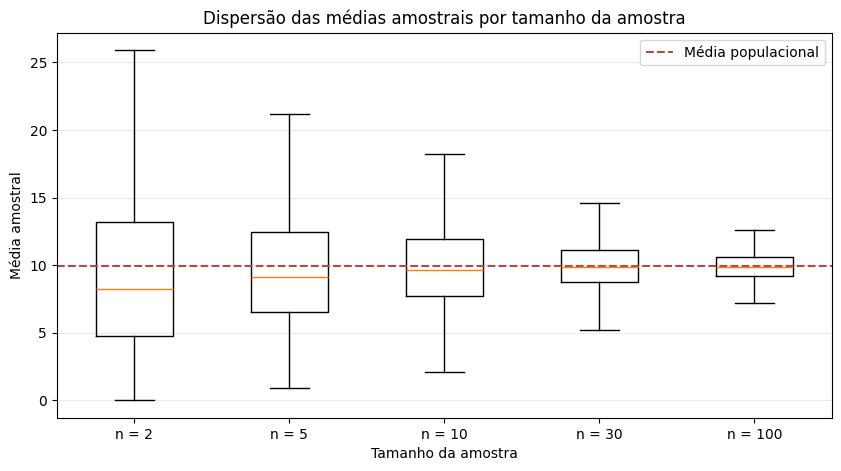

In [5]:
dados_boxplot = [
    medias_amostrais[tamanho]
    for tamanho in TAMANHOS_AMOSTRA
]

plt.figure(figsize=(10, 5))
plt.boxplot(
    dados_boxplot,
    tick_labels=[f"n = {tamanho}" for tamanho in TAMANHOS_AMOSTRA],
    showfliers=False
)
plt.axhline(
    media_populacional,
    color="#b04a4a",
    linestyle="--",
    label="Média populacional"
)
plt.title("Dispersão das médias amostrais por tamanho da amostra")
plt.xlabel("Tamanho da amostra")
plt.ylabel("Média amostral")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.show()

## 6. Pergunta: o erro padrão observado corresponde ao valor teórico?

O desvio-padrão das médias amostrais obtidas por simulação é uma estimativa empírica do erro padrão. A tabela compara esse valor com o erro padrão teórico, calculado a partir do desvio-padrão da população simulada.

In [6]:
resultados = []

for tamanho in TAMANHOS_AMOSTRA:
    medias = medias_amostrais[tamanho]
    erro_padrao_teorico = desvio_padrao_populacional / np.sqrt(tamanho)
    erro_padrao_empirico = medias.std(ddof=1)

    resultados.append({
        "Tamanho da amostra": tamanho,
        "Média das médias": medias.mean(),
        "Média populacional": media_populacional,
        "Erro padrão teórico": erro_padrao_teorico,
        "Erro padrão empírico": erro_padrao_empirico
    })

tabela_resultados = pd.DataFrame(resultados)

tabela_resultados.round(3)

,Tamanho da amostra,Média das médias,Média populacional,Erro padrão teórico,Erro padrão empírico
0,2,9.843,9.949,7.064,7.011
1,5,9.839,9.949,4.468,4.488
2,10,9.982,9.949,3.159,3.155
3,30,9.940,9.949,1.824,1.790
4,100,9.926,9.949,0.999,0.991


## 7. Interpretação

A média das médias amostrais tende a ficar próxima da média da população simulada. A dispersão das médias tende a diminuir com o aumento do tamanho da amostra, em concordância com a relação $EP(\bar{X}) = \sigma/\sqrt{n}$.

A aproximação da distribuição das médias a uma forma normal pode ser observada nos histogramas, mas sua velocidade depende da forma da população e do tamanho amostral. A simulação ilustra o comportamento esperado, mas não substitui a justificativa teórica nem demonstra que toda amostra de tamanho específico produzirá uma distribuição normal.

Nesta atividade, as observações são amostradas com reposição. Em situações de amostragem sem reposição de uma população finita, o cálculo do erro padrão pode exigir uma correção para população finita.